In [ ]:
#Install Java and PySpark in Google Colab
!apt-get install openjdk-8-jdk-headless -qq > /dev/null
!pip install -q pyspark tensorflow scikit-learn seaborn matplotlib

root
 |-- id: string (nullable = true)
 |-- text: string (nullable = true)
 |-- author: string (nullable = true)

+------+-----+
|author|count|
+------+-----+
|   MWS| 6044|
|   HPL| 5635|
|   EAP| 7900|
+------+-----+

+-------+------------------+
|summary|        word_count|
+-------+------------------+
|  count|             19579|
|   mean|26.730476530977068|
| stddev|19.048353080110637|
|    min|                 2|
|    max|               861|
+-------+------------------+



Model: "sequential_17"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_17 (Embedding)        │ (None, 100, 64)        │       640,064 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_17 (LSTM)                  │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_18 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 743,107 (2.83 MB)

 Trainable params: 743,107 (2.83 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/8
245/245 - 126s - 515ms/step - accuracy: 0.6536 - loss: 0.7650 - val_accuracy: 0.8095 - val_loss: 0.4828
Epoch 2/8
245/245 - 122s - 498ms/step - accuracy: 0.8650 - loss: 0.3591 - val_accuracy: 0.8350 - val_loss: 0.4451
Epoch 3/8
245/245 - 142s - 579ms/step - accuracy: 0.9153 - loss: 0.2394 - val_accuracy: 0.8169 - val_loss: 0.5139
Epoch 4/8
245/245 - 123s - 503ms/step - accuracy: 0.9351 - loss: 0.1860 - val_accuracy: 0.8238 - val_loss: 0.5257
123/123 ━━━━━━━━━━━━━━━━━━━━ 11s 83ms/step

--- Classification Report ---
              precision    recall  f1-score   support

         EAP       0.80      0.88      0.84      1580
         HPL       0.87      0.79      0.82      1127
         MWS       0.86      0.82      0.84      1209

    accuracy                           0.84      3916
   macro avg       0.84      0.83      0.83      3916
weighted avg       0.84      0.84      0.83      3916



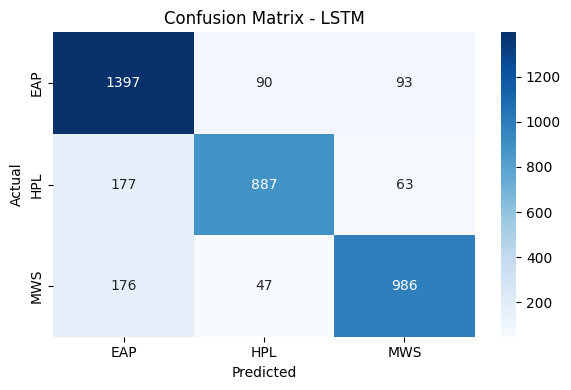

+------+-----+-----+
|author|label|count|
+------+-----+-----+
|   EAP|    0| 7900|
|   HPL|    1| 5635|
|   MWS|    2| 6044|
+------+-----+-----+


--- Training Optimized Bidirectional Model ---
Epoch 1/8


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


245/245 - 7s - 29ms/step - accuracy: 0.6418 - loss: 0.7839 - val_accuracy: 0.8082 - val_loss: 0.4856
Epoch 2/8
245/245 - 4s - 14ms/step - accuracy: 0.8699 - loss: 0.3488 - val_accuracy: 0.8315 - val_loss: 0.4541
Epoch 3/8
245/245 - 4s - 17ms/step - accuracy: 0.9226 - loss: 0.2240 - val_accuracy: 0.8039 - val_loss: 0.5962
Epoch 4/8
245/245 - 3s - 14ms/step - accuracy: 0.9379 - loss: 0.1746 - val_accuracy: 0.8036 - val_loss: 0.6072
123/123 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step

--- Optimized Bidirectional LSTM Classification Report ---
              precision    recall  f1-score   support

         EAP       0.84      0.85      0.84      1580
         HPL       0.82      0.83      0.83      1127
         MWS       0.83      0.80      0.82      1209

    accuracy                           0.83      3916
   macro avg       0.83      0.83      0.83      3916
weighted avg       0.83      0.83      0.83      3916



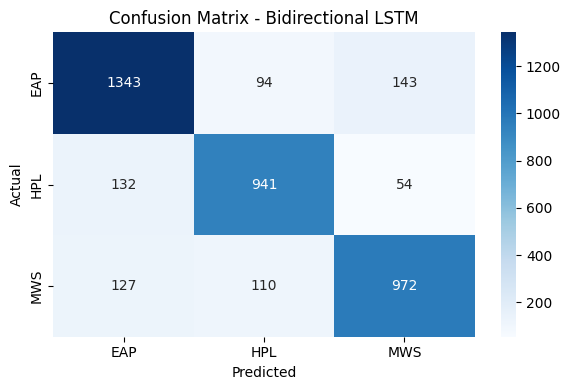

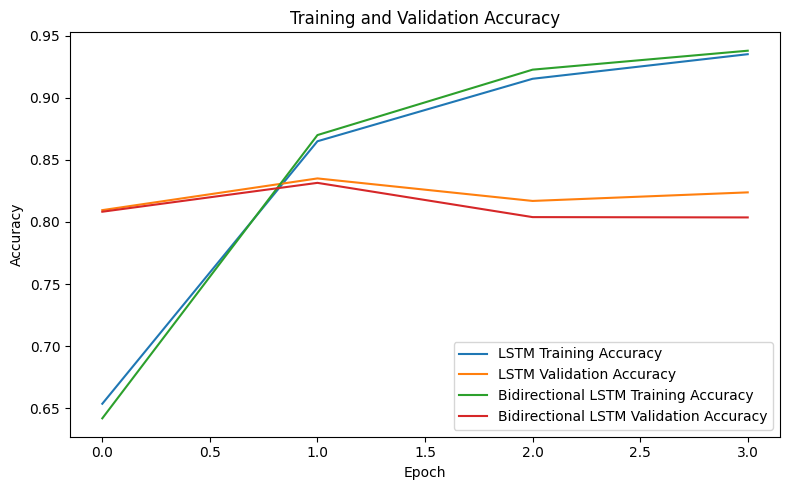

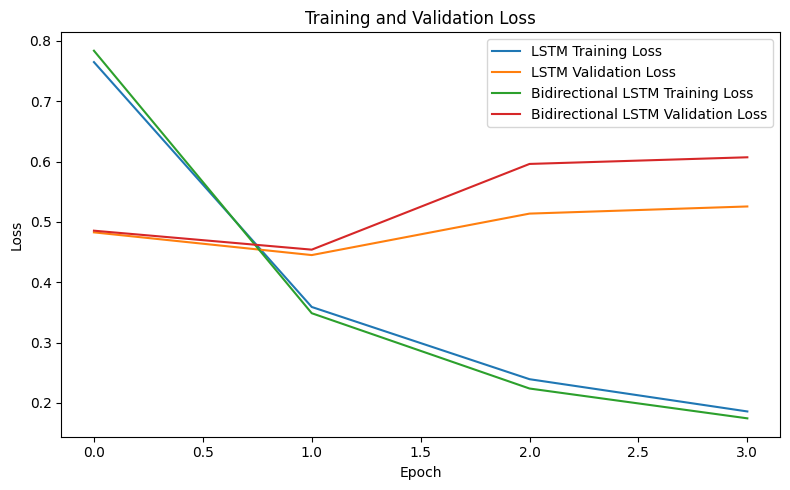

In [ ]:
import os
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pyspark.sql import SparkSession
from pyspark.sql.functions import col, lower, regexp_replace, split, size
from pyspark.ml.feature import StringIndexer, Tokenizer, HashingTF

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout, Bidirectional
from tensorflow.keras.preprocessing.text import Tokenizer as KerasTokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import tensorflow.keras.callbacks as callbacks

#Starting the PySpark Session
spark = SparkSession.builder \
    .master("local[*]") \
    .appName("SpookyAuthorAssignment") \
    .getOrCreate()

#Downloading the dataset
data_url = "https://raw.githubusercontent.com/spopov812/Kaggle-Author-Identification/master/train.csv" #(Spopov, 2017)
file_name = "spooky_authors.csv"

if not os.path.exists(file_name):
    urllib.request.urlretrieve(data_url, file_name)

#Converts CSV file into the PySpark DataFrame
df = spark.read.csv(file_name, header=True, inferSchema=True, multiLine=True, escape='"')

#Shows the schema and counts per author in dataset
df.printSchema()

#Filter out the malformed CSV rows to ensure only author classes exist
valid_authors = ["EAP", "HPL", "MWS"]
df = df.filter(col("author").isin(valid_authors))
df.groupBy("author").count().show()

#Make the text lower case and remove punctuation
df_clean = df.filter(col("text").isNotNull() & col("author").isNotNull())
df_clean = df_clean.withColumn("clean_text", lower(regexp_replace(col("text"), r"[^\w\s]", "")))

#Get the word counts to see the lengths of text
df_clean = df_clean.withColumn("word_count", size(split(col("clean_text"), " ")))
df_clean.select("word_count").describe().show()

#Convert the author names into numbers (0, 1, 2)
from pyspark.sql.functions import when

df_indexed = df_clean.withColumn(
    "label",
    when(col("author") == "EAP", 0)
    .when(col("author") == "HPL", 1)
    .when(col("author") == "MWS", 2)
    .otherwise(-1)
)

df_indexed = df_indexed.filter(col("label") != -1)

author_names = ["EAP", "HPL", "MWS"]

#Tokenize each sentence into list of words
tokenizer = Tokenizer(inputCol="clean_text", outputCol="words")

df_words = tokenizer.transform(df_indexed)

#Convert words into fixed-size feature vectors using HashingTF
hashingTF = HashingTF(inputCol="words", outputCol="features", numFeatures=5000)

df_features = hashingTF.transform(df_words)

#Convert Spark DataFrame to Pandas so Keras can easily train the data
data = df_features.select("clean_text", "label").toPandas().dropna()

#Map words to numbers manually for LSTM sequence input
MAX_WORDS = 10000
MAX_LEN = 100

#Build a word index dictionary
keras_tokenizer = KerasTokenizer(num_words=MAX_WORDS, oov_token="<OOV>")
keras_tokenizer.fit_on_texts(data['clean_text'])
sequences = keras_tokenizer.texts_to_sequences(data['clean_text'])

#Convert the text rows to number sequences with padding
X = pad_sequences(sequences, maxlen=MAX_LEN, padding='post', truncating='post')

y = data['label'].astype(int).values

#A Stratified split to make sure all author classes are represented in the train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

tf.keras.utils.set_random_seed(42)

model = Sequential()
model.add(Embedding(input_dim=MAX_WORDS + 1, output_dim=64, mask_zero=True))
model.add(LSTM(128, dropout=0.2, recurrent_dropout=0.1))
model.add(Dense(32, activation='relu'))
model.add(Dropout(0.2))
model.add(Dense(3, activation='softmax'))

model.build(input_shape=(None, MAX_LEN))

model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    metrics=['accuracy']
)

model.summary()

early_stopping = callbacks.EarlyStopping(
    monitor='val_loss',
    patience=2,
    restore_best_weights=True
)

#Training the model (Apache Software Foundation, 2023; Google TensorFlow, 2023)
early_stopping = callbacks.EarlyStopping(
    monitor='val_loss',
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=8,
    batch_size=64,
    validation_data=(X_test, y_test),
    callbacks=[
        callbacks.TerminateOnNaN(),
        early_stopping
    ],
    verbose=2
)

#Evaluating the model
predictions = model.predict(X_test)
y_pred = np.argmax(predictions, axis=1)


print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred, target_names=author_names))

#Plot the confusion matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=author_names, yticklabels=author_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - LSTM')
plt.tight_layout()
plt.show()

df_indexed.groupBy("author", "label").count().orderBy("label").show()


#Retrain the model using a Bidirectional LSTM layer for better performance (Apache Software Foundation, 2023; Google TensorFlow, 2023)
opt_model = Sequential()
opt_model.add(Embedding(input_dim=MAX_WORDS + 1, output_dim=64, input_length=MAX_LEN))
opt_model.add(Bidirectional(LSTM(64)))
opt_model.add(Dropout(0.4))
opt_model.add(Dense(3, activation='softmax'))

opt_model.compile(loss='sparse_categorical_crossentropy', optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), metrics=['accuracy'])

print("\n--- Training Optimized Bidirectional Model ---")

opt_early_stopping = callbacks.EarlyStopping(

    monitor='val_loss',
    patience=2,
    restore_best_weights=True
)

opt_history = opt_model.fit(
    X_train,
    y_train,

    epochs=8,
    batch_size=64,
    validation_data=(X_test, y_test),
    callbacks=[
        callbacks.TerminateOnNaN(),
        opt_early_stopping
    ],
    verbose=2
)

#Evaluate the optimized model
opt_predictions = opt_model.predict(X_test)
opt_y_pred = np.argmax(opt_predictions, axis=1)

print("\n--- Optimized Bidirectional LSTM Classification Report ---")
print(classification_report(y_test, opt_y_pred, target_names=author_names))

#Plot the confusion matrix for the optimized model
opt_cm = confusion_matrix(y_test, opt_y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(opt_cm, annot=True, fmt='d', cmap='Blues', xticklabels=author_names, yticklabels=author_names)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Bidirectional LSTM')
plt.tight_layout()
plt.show()

#Plot training and validation accuracy for both models
plt.figure(figsize=(8, 5))
plt.plot(history.history['accuracy'], label='LSTM Training Accuracy')
plt.plot(history.history['val_accuracy'], label='LSTM Validation Accuracy')
plt.plot(opt_history.history['accuracy'], label='Bidirectional LSTM Training Accuracy')
plt.plot(opt_history.history['val_accuracy'], label='Bidirectional LSTM Validation Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()
plt.tight_layout()
plt.show()

#Plot training and validation loss for both models
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='LSTM Training Loss')
plt.plot(history.history['val_loss'], label='LSTM Validation Loss')
plt.plot(opt_history.history['loss'], label='Bidirectional LSTM Training Loss')
plt.plot(opt_history.history['val_loss'], label='Bidirectional LSTM Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.tight_layout()
plt.show()